# Decision Tree on Adult Census Dataset

This notebook applies the **Decision Tree** classifier to the Adult Census Income dataset
as part of the COMM075 group coursework.

It will:
- inspect the cleaned Adult Census data,
- train a baseline `DecisionTreeClassifier`,
- tune hyperparameters using 5-fold stratified cross-validation,
- evaluate the final model with multiple metrics (Accuracy, F1, ROC-AUC),
- generate report-ready figures and tables.

**Prediction task:** classify whether a person's annual income exceeds $50K (binary: 0 = <=50K, 1 = >50K).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Fix seed for reproducibility across all stochastic steps
RANDOM_STATE = 42

In [2]:
def find_project_root(start: Path) -> Path:
    """Walk up from *start* until we find the datasets/cleaned directory."""
    for candidate in [start, *start.parents]:
        if (candidate / "datasets" / "cleaned" / "X_train.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate project root.")

PROJECT_ROOT = find_project_root(Path.cwd())
CLEANED_DIR  = PROJECT_ROOT / "datasets" / "cleaned"
OUTPUT_DIR   = PROJECT_ROOT / "Decision_Tree" / "outputs_adult"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Cleaned dir  :", CLEANED_DIR)
print("Output dir   :", OUTPUT_DIR)

Project root : /user/HS401/sn01556/Desktop/MLDS/mlds-group5-project
Cleaned dir  : /user/HS401/sn01556/Desktop/MLDS/mlds-group5-project/datasets/cleaned
Output dir   : /user/HS401/sn01556/Desktop/MLDS/mlds-group5-project/Decision_Tree/outputs_adult


## Data Loading and Inspection

In [3]:
# Adult Census uses a train/test split (no separate validation file).
# The test set acts as the held-out evaluation set throughout this notebook.
X_train = pd.read_csv(CLEANED_DIR / "X_train.csv")
X_test  = pd.read_csv(CLEANED_DIR / "X_test.csv")
y_train = pd.read_csv(CLEANED_DIR / "y_train.csv")["income"]
y_test  = pd.read_csv(CLEANED_DIR / "y_test.csv")["income"]

print("X_train shape:", X_train.shape)
print("X_test  shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test  shape:", y_test.shape)

X_train shape: (24111, 12)
X_test  shape: (6028, 12)
y_train shape: (24111,)
y_test  shape: (6028,)


In [4]:
inspection_summary = pd.DataFrame({
    "dtype":        X_train.dtypes.astype(str),
    "train_missing": X_train.isna().sum(),
    "test_missing":  X_test.isna().sum(),
    "unique_values": X_train.nunique(),
})
inspection_summary

,dtype,train_missing,test_missing,unique_values
age,float64,0,0,72
workclass,float64,0,0,7
education.num,float64,0,0,16
marital.status,float64,0,0,7
occupation,float64,0,0,14
relationship,float64,0,0,6
race,float64,0,0,5
sex,float64,0,0,2
capital.gain,float64,0,0,115
capital.loss,float64,0,0,84


In [5]:
print("Training target distribution (income: 0=<=50K, 1=>50K)")
display(y_train.value_counts().rename("count").to_frame())
display((y_train.value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

print("Test target distribution")
display(y_test.value_counts().rename("count").to_frame())
display((y_test.value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

Training target distribution (income: 0=<=50K, 1=>50K)


,count
income,
0,18106
1,6005


,percent
income,
0,75.09
1,24.91


Test target distribution


,count
income,
0,4527
1,1501


,percent
income,
0,75.1
1,24.9


In [6]:
train_with_target = X_train.copy()
train_with_target["income"] = y_train

feature_corr = (
    train_with_target.corr(numeric_only=True)["income"]
    .drop("income")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
feature_corr.to_frame("correlation_with_income")

,correlation_with_income
education.num,0.333042
capital.gain,0.286909
relationship,-0.252743
age,0.239621
hours.per.week,0.232280
sex,0.218191
marital.status,-0.189373
capital.loss,0.137566
race,0.069804
occupation,0.054421


## Baseline Model

A default (unpruned) Decision Tree trained on the full training set. Establishes the reference performance before tuning.

In [7]:
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name="Model"):
    y_train_pred  = model.predict(X_train)
    y_test_pred   = model.predict(X_test)
    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_test_proba  = model.predict_proba(X_test)[:, 1]

    metrics = pd.DataFrame(
        {
            "Accuracy": [accuracy_score(y_train, y_train_pred), accuracy_score(y_test, y_test_pred)],
            "F1":       [f1_score(y_train, y_train_pred),       f1_score(y_test, y_test_pred)],
            "ROC_AUC":  [roc_auc_score(y_train, y_train_proba), roc_auc_score(y_test, y_test_proba)],
        },
        index=["Train", "Test"],
    ).round(4)

    print(model_name)
    display(metrics)
    print("Test classification report")
    print(classification_report(y_test, y_test_pred, digits=4))

    return {
        "metrics":       metrics,
        "y_test_pred":   y_test_pred,
        "y_test_proba":  y_test_proba,
        "y_train_pred":  y_train_pred,
        "y_train_proba": y_train_proba,
    }

In [8]:
baseline_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_tree.fit(X_train, y_train)

baseline_results = evaluate_model(
    baseline_tree, X_train, y_train, X_test, y_test,
    model_name="Baseline Decision Tree",
)

Baseline Decision Tree


,Accuracy,F1,ROC_AUC
Train,0.9777,0.9537,0.9985
Test,0.8130,0.6207,0.7715


Test classification report
              precision    recall  f1-score   support

           0     0.8730    0.8789    0.8759      4527
           1     0.6272    0.6143    0.6207      1501

    accuracy                         0.8130      6028
   macro avg     0.7501    0.7466    0.7483      6028
weighted avg     0.8118    0.8130    0.8124      6028



In [9]:
# StratifiedKFold preserves the ~75/25 class ratio in every fold — important for this imbalanced dataset.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

baseline_cv = cross_validate(
    baseline_tree, X_train, y_train,
    cv=cv, scoring=scoring, return_train_score=False,
)

baseline_cv_summary = pd.DataFrame({
    metric: [baseline_cv[f"test_{metric}"].mean(), baseline_cv[f"test_{metric}"].std()]
    for metric in scoring
}, index=["mean", "std"]).round(4)

print("Baseline 5-fold CV summary")
baseline_cv_summary

Baseline 5-fold CV summary


,accuracy,f1,roc_auc
mean,0.8067,0.6100,0.7572
std,0.0034,0.0072,0.0038


## Hyperparameter Tuning

GridSearchCV over key tree parameters. Optimising for F1 because accuracy is misleading on the imbalanced 75/25 income split.

In [10]:
# Search over splitting criterion, depth, sample constraints, and class weighting.
# class_weight='balanced' upweights the minority class (>50K) — critical for F1 on this dataset.
# max_depth is the primary lever against overfitting on the 24k-sample training set.
param_grid = {
    "criterion":        ["gini", "entropy"],
    "max_depth":        [3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf":  [1, 2, 4, 8],
    "class_weight":     [None, "balanced"],
}

# Optimise for F1 because accuracy is misleading on an imbalanced target.
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,  # refit best model on full training set automatically
    verbose=1,
)

grid_search.fit(X_train, y_train)

print("Best CV F1:", round(grid_search.best_score_, 4))
print("Best parameters:")
grid_search.best_params_

Fitting 5 folds for each of 448 candidates, totalling 2240 fits
Best CV F1: 0.6816
Best parameters:


{'class_weight': 'balanced',
 'criterion': 'entropy',
 'max_depth': 10,
 'min_samples_leaf': 8,
 'min_samples_split': 20}

In [11]:
cv_results = pd.DataFrame(grid_search.cv_results_)
top_models = cv_results.sort_values("rank_test_score").loc[:, [
    "rank_test_score", "mean_test_score", "std_test_score",
    "param_criterion", "param_max_depth",
    "param_min_samples_split", "param_min_samples_leaf",
    "param_class_weight",
]].head(10)
top_models

,rank_test_score,mean_test_score,std_test_score,param_criterion,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_class_weight
431,1,0.681632,0.004459,entropy,10,20,8,balanced
294,2,0.681469,0.004975,gini,8,10,2,balanced
293,3,0.681383,0.004401,gini,8,5,2,balanced
292,4,0.681298,0.004436,gini,8,2,2,balanced
295,5,0.681046,0.005500,gini,8,20,2,balanced
290,6,0.680943,0.004691,gini,8,10,1,balanced
430,7,0.680886,0.004656,entropy,10,10,8,balanced
429,7,0.680886,0.004656,entropy,10,5,8,balanced
428,7,0.680886,0.004656,entropy,10,2,8,balanced
297,10,0.680740,0.004959,gini,8,5,4,balanced


In [12]:
# best_estimator_ is already refit on the full X_train by GridSearchCV (refit=True).
best_tree = grid_search.best_estimator_

best_results = evaluate_model(
    best_tree, X_train, y_train, X_test, y_test,
    model_name="Tuned Decision Tree",
)

Tuned Decision Tree


,Accuracy,F1,ROC_AUC
Train,0.8103,0.6998,0.9206
Test,0.7998,0.6821,0.9016


Test classification report
              precision    recall  f1-score   support

           0     0.9448    0.7789    0.8539      4527
           1     0.5640    0.8628    0.6821      1501

    accuracy                         0.7998      6028
   macro avg     0.7544    0.8208    0.7680      6028
weighted avg     0.8500    0.7998    0.8111      6028



In [13]:
comparison_table = pd.concat(
    {"Baseline": baseline_results["metrics"], "Tuned": best_results["metrics"]},
    axis=0,
).reset_index().rename(columns={"level_0": "Model", "level_1": "Split"})

print("Metrics comparison: Baseline vs Tuned")
comparison_table

Metrics comparison: Baseline vs Tuned


,Model,Split,Accuracy,F1,ROC_AUC
0,Baseline,Train,0.9777,0.9537,0.9985
1,Baseline,Test,0.8130,0.6207,0.7715
2,Tuned,Train,0.8103,0.6998,0.9206
3,Tuned,Test,0.7998,0.6821,0.9016


## Tuned Model Cross-Validation Summary

In [14]:
# Re-run CV on the tuned model using the same folds as baseline for a fair comparison.
tuned_cv = cross_validate(
    best_tree, X_train, y_train,
    cv=cv, scoring=scoring, return_train_score=False,
)

tuned_cv_summary = pd.DataFrame({
    metric: [tuned_cv[f"test_{metric}"].mean(), tuned_cv[f"test_{metric}"].std()]
    for metric in scoring
}, index=["mean", "std"]).round(4)

cv_comparison = pd.concat(
    {"Baseline": baseline_cv_summary, "Tuned": tuned_cv_summary}, axis=0,
).reset_index().rename(columns={"level_0": "Model", "level_1": "Stat"})

print("Cross-Validation comparison (5-fold, on training set)")
display(cv_comparison)

Cross-Validation comparison (5-fold, on training set)


,Model,Stat,accuracy,f1,roc_auc
0,Baseline,mean,0.8067,0.6100,0.7572
1,Baseline,std,0.0034,0.0072,0.0038
2,Tuned,mean,0.7997,0.6816,0.8967
3,Tuned,std,0.0043,0.0045,0.0016


## Confusion Matrix

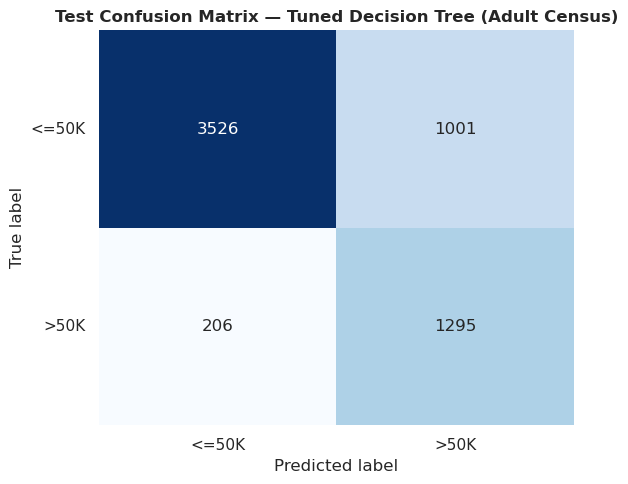

In [15]:
cm = confusion_matrix(y_test, best_results["y_test_pred"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Test Confusion Matrix — Tuned Decision Tree (Adult Census)", fontweight="bold")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticklabels(["<=50K", ">50K"], rotation=0)
ax.set_yticklabels(["<=50K", ">50K"], rotation=0)
plt.tight_layout()
# dpi=200 keeps file size reasonable while staying sharp in the report
plt.savefig(OUTPUT_DIR / "confusion_matrix_test.png", dpi=200, bbox_inches="tight")
plt.show()

## ROC Curve

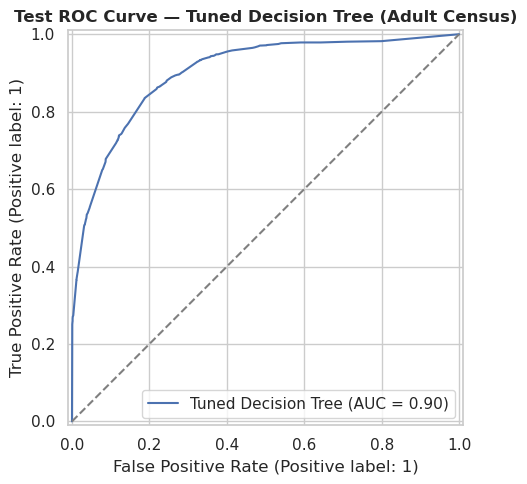

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, best_results["y_test_proba"], ax=ax, name="Tuned Decision Tree")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_title("Test ROC Curve — Tuned Decision Tree (Adult Census)", fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve_test.png", dpi=200, bbox_inches="tight")
plt.show()

## ROC Curve Comparison: Baseline vs Tuned

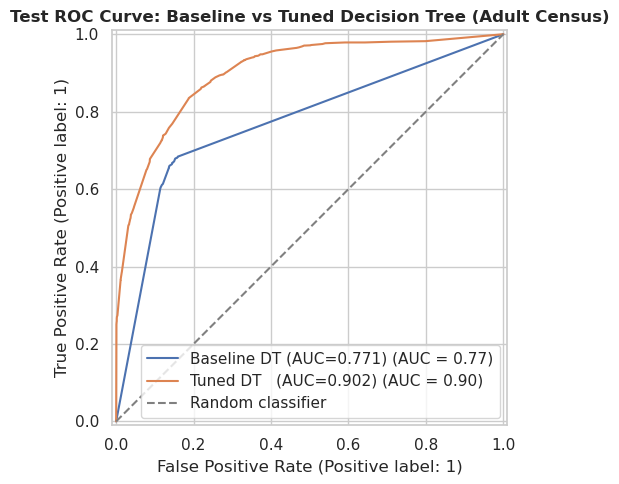

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test, baseline_results["y_test_proba"], ax=ax,
    name=f"Baseline DT (AUC={baseline_results['metrics'].loc['Test', 'ROC_AUC']:.3f})",
)
RocCurveDisplay.from_predictions(
    y_test, best_results["y_test_proba"], ax=ax,
    name=f"Tuned DT   (AUC={best_results['metrics'].loc['Test', 'ROC_AUC']:.3f})",
)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("Test ROC Curve: Baseline vs Tuned Decision Tree (Adult Census)", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## Feature Importance

In [18]:
feature_importance = pd.DataFrame({
    "feature":    X_train.columns,
    "importance": best_tree.feature_importances_,
}).sort_values("importance", ascending=False)

feature_importance

,feature,importance
5,relationship,0.423415
2,education.num,0.181226
8,capital.gain,0.162889
0,age,0.085741
10,hours.per.week,0.057337
9,capital.loss,0.044055
4,occupation,0.029344
7,sex,0.005753
1,workclass,0.005682
6,race,0.001999


/tmp/ipykernel_141262/1507140734.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance, x="importance", y="feature", palette="viridis", ax=ax)


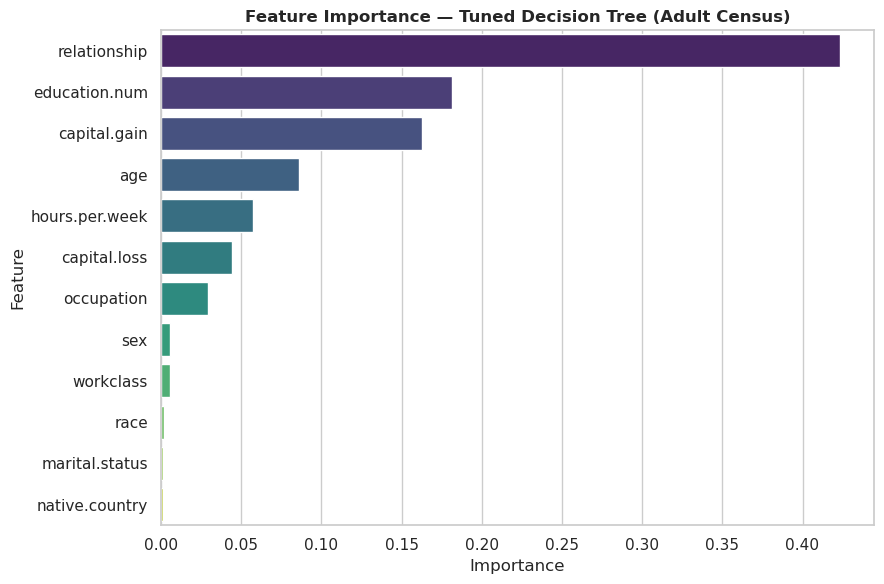

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=feature_importance, x="importance", y="feature", palette="viridis", ax=ax)
ax.set_title("Feature Importance — Tuned Decision Tree (Adult Census)", fontweight="bold")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

## Zero-Importance Features

In [20]:
# Features with zero importance were never chosen as a split criterion by the tuned tree.
zero_importance    = feature_importance[feature_importance["importance"] == 0]
nonzero_importance = feature_importance[feature_importance["importance"] > 0]

print(f"Features used by the tree ({len(nonzero_importance)}):")
display(nonzero_importance.reset_index(drop=True))

print(f"\nFeatures with zero importance — never selected as a split ({len(zero_importance)}):")
display(zero_importance.reset_index(drop=True))

Features used by the tree (12):


,feature,importance
0,relationship,0.423415
1,education.num,0.181226
2,capital.gain,0.162889
3,age,0.085741
4,hours.per.week,0.057337
5,capital.loss,0.044055
6,occupation,0.029344
7,sex,0.005753
8,workclass,0.005682
9,race,0.001999



Features with zero importance — never selected as a split (0):


,feature,importance


## Tree Visualisation

Limited to the top 3 levels for readability in the report.

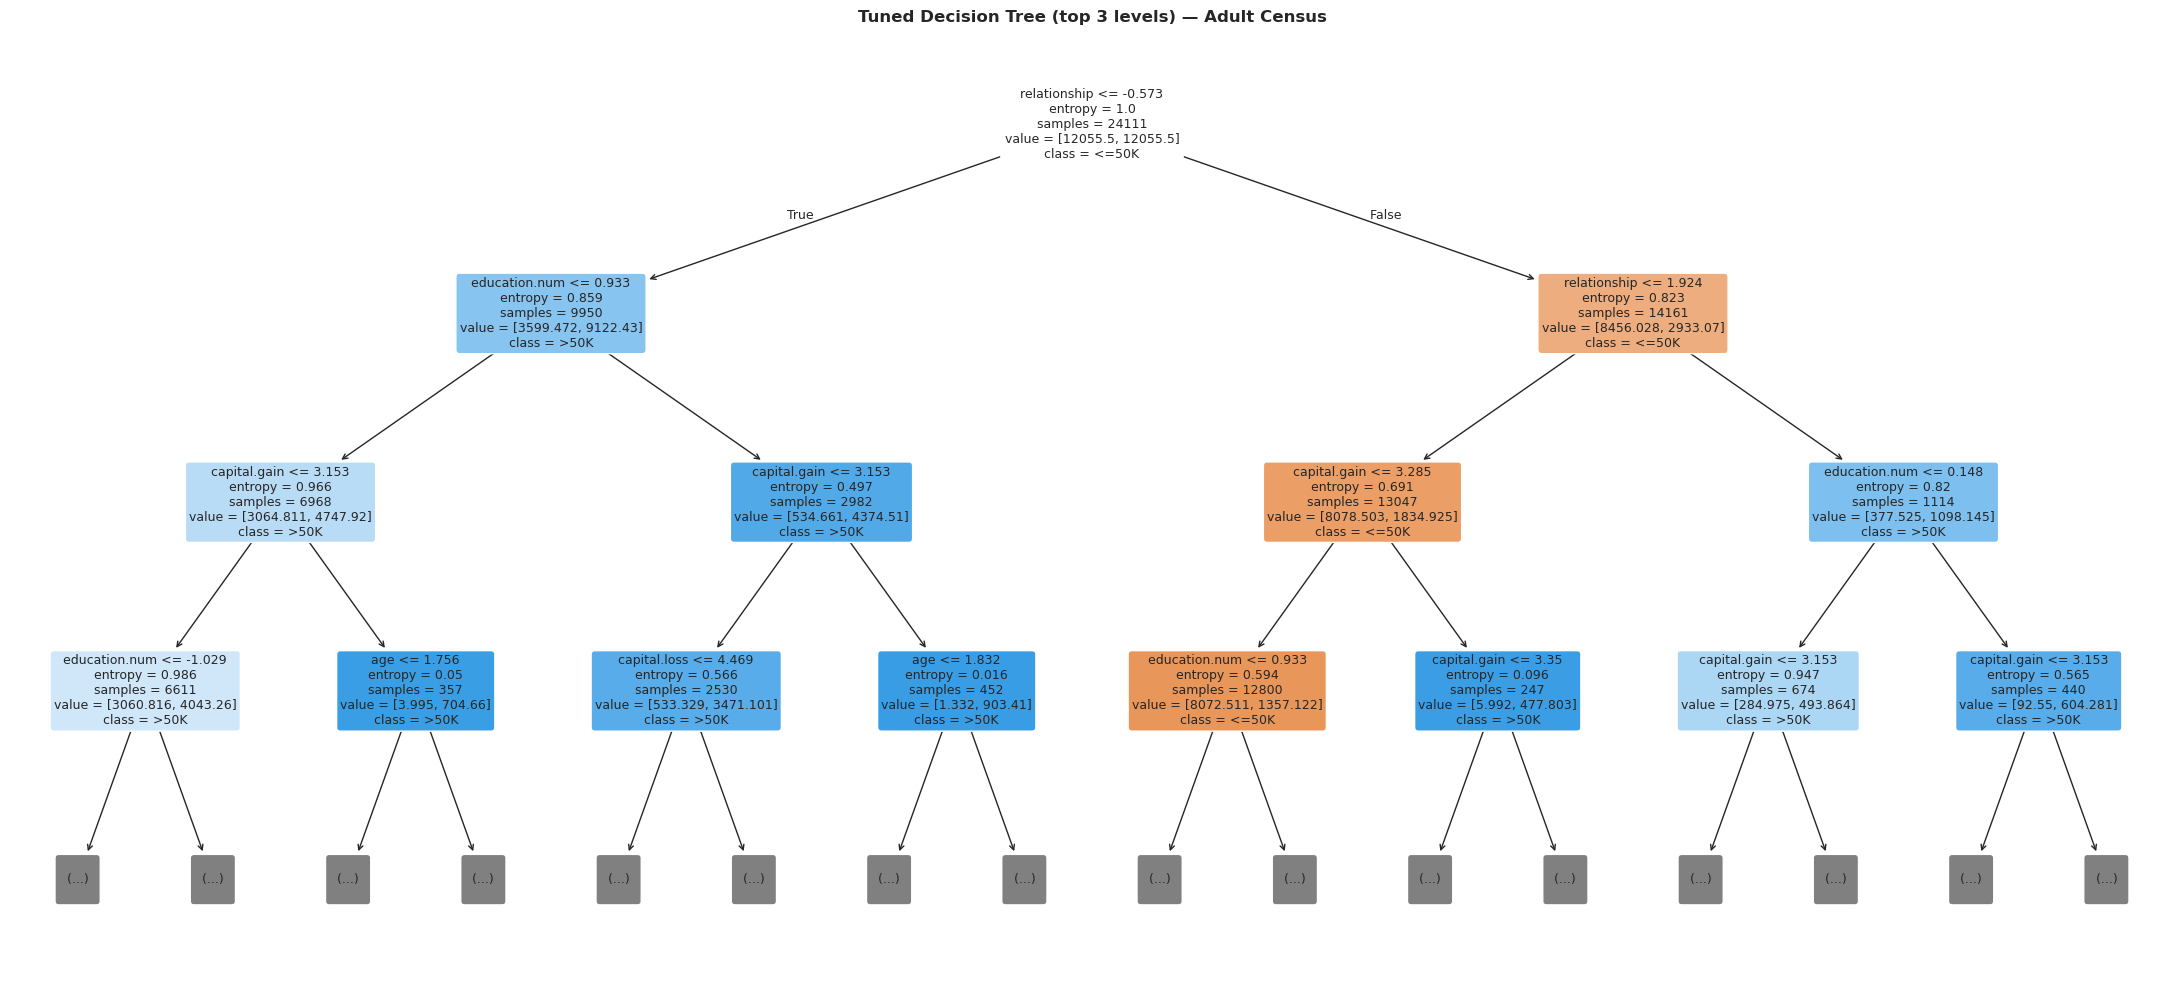

In [21]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    best_tree,
    feature_names=X_train.columns,
    class_names=["<=50K", ">50K"],
    filled=True, rounded=True, fontsize=9, max_depth=3, ax=ax,
)
ax.set_title("Tuned Decision Tree (top 3 levels) — Adult Census", fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "decision_tree_top_levels.png", dpi=200, bbox_inches="tight")
plt.show()

## Save Outputs

In [22]:
comparison_table.to_csv(OUTPUT_DIR / "dt_adult_metrics_comparison.csv", index=False)
feature_importance.to_csv(OUTPUT_DIR / "dt_adult_feature_importance.csv", index=False)
top_models.to_csv(OUTPUT_DIR / "dt_adult_top_gridsearch_results.csv", index=False)

print("Saved outputs:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Saved outputs:
- confusion_matrix_test.png
- decision_tree_top_levels.png
- dt_adult_feature_importance.csv
- dt_adult_metrics_comparison.csv
- dt_adult_top_gridsearch_results.csv
- feature_importance.png
- roc_curve_comparison.png
- roc_curve_test.png
